In [3]:
import os.path as osp
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
#from ipywidgets import IntSlider, BoundedIntText, HBox, Layout, jslink, interactive_output
#from IPython.display import display
#from scipy.signal import welch

In [22]:
filename = Path("20261015_15h05m32_dsum_coincidence_H62_NZKF_time_25V_180s.csv")
filedir = Path("~/pdc/data/DSUM_101526")

file = (filedir / filename).expanduser()
print(f"Running file at {file}")

all_data = pd.read_csv(file, delimiter=';')
print(f"Lines read: {len(all_data):,} with columns {list(all_data.columns)}")

Running file at /home/p6k/pdc/data/DSUM_101526/20261015_15h05m32_dsum_coincidence_H62_NZKF_time_25V_180s.csv
Lines read: 909,460 with columns ['pdcIdx', 'frameIdx', 'dataIdx', 'dsum']


In [25]:
# Ceate a 2D array for each PDC
pdc_split = {pdc: pdc_data.groupby(["frameIdx", "dataIdx"])["dsum"].sum().unstack(fill_value=0).to_numpy() for pdc, pdc_data in all_data.groupby("pdcIdx")}
pdc_num = len(pdc_split)
frame_num = len(pdc_split[0])

print(f"Read {frame_num:,} frames across {pdc_num} PDCs")

Read 1,829 frames across 4 PDCs


### Check average counts across frames and timeacross

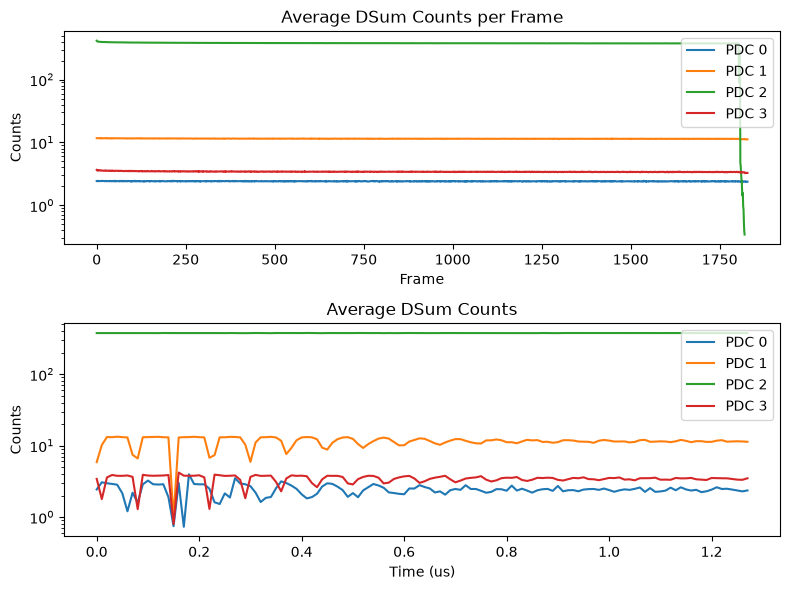

In [48]:
fig, ax = plt.subplots(2,1,figsize=(8,6))
for pdc, data in pdc_split.items():
    avg = np.mean(data, axis=1)
    ax[0].plot(avg, label=f"PDC {pdc}")
    avg = np.mean(data, axis=0)
    times_us = [x*.01 for x in range(len(avg))]
    ax[1].plot(times_us, avg, label=f"PDC {pdc}")
    
ax[0].set_title("Average DSum Counts per Frame")
ax[0].set_xlabel("Frame")
ax[1].set_title("Average DSum Counts")
ax[1].set_xlabel("Time (us)")

for axis in ax:
    axis.set_ylabel("Counts")
    axis.set_yscale("log")
    axis.legend()
plt.tight_layout()
plt.show()

### Interactive Per-Frame Plotter

In [49]:
def show(frame):
    plt.figure(figsize=(8, 3))
    for pdc, d in df[frame].items():
        plt.plot(d["dataIdx"], d["dsum"], label=f"PDC {pdc}")
    plt.title(f"Frame {frame}")
    plt.xlabel("Index")
    plt.ylabel("DSum")
    plt.yscale("log")
    plt.legend()
    plt.show()

fr = sorted(df)
slider = IntSlider(min=fr[0], max=fr[-1], continuous_update=False, layout=Layout(width="700px"))
box = BoundedIntText(min=fr[0], max=fr[-1], layout=Layout(width="90px"))
jslink((slider, "value"), (box, "value"))

display(HBox([slider, box]), interactive_output(show, {"frame": slider}))

NameError: name 'IntSlider' is not defined

### Interactive Per-Frame FFT

In [9]:
def show_psd(frame):
    plt.figure(figsize=(8, 3))
    for pdc, d in df.get(frame, {}).items():
        f, p = welch(d["dsum"].to_numpy(), fs=1e8, nperseg=100, window="hann", detrend="constant")
        plt.plot(f / 1e6, p, label=f"PDC {pdc}")
    plt.title(f"Frame {frame}: PSD")
    plt.xlabel("Frequency (MHz)")
    plt.ylabel("PSD (dsum² / Hz)")
    plt.yscale("log")
    plt.legend()
    plt.show()


fr = sorted(df)
slider = IntSlider(min=fr[0], max=fr[-1], continuous_update=False, layout=Layout(width="700px"))
box = BoundedIntText(min=fr[0], max=fr[-1], layout=Layout(width="90px"))
jslink((slider, "value"), (box, "value"))

display(HBox([slider, box]), interactive_output(show_psd, {"frame": slider}))

Output()